## 1. Importing libraries and configure the notebook


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

SELECTED_CITIES = ["Delhi", "Bengaluru", "Lucknow", "Chennai", "Hyderabad"]
print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Locate and load the dataset

In [6]:
PROJECT_ROOT = Path.cwd().parent
DATASET_PATH = PROJECT_ROOT / "dataset" / "raw" / "city_day.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATASET_PATH)
print("Dataset exists:", DATASET_PATH.exists())

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Could not find dataset at {DATASET_PATH}. "
        "Check that city_day.csv is inside dataset/raw/."
    )

df = pd.read_csv(DATASET_PATH)
print("Dataset loaded successfully.")
print("Original dataset shape:", df.shape)


Project root: g:\AQI
Dataset path: g:\AQI\dataset\raw\city_day.csv
Dataset exists: True
Dataset loaded successfully.
Original dataset shape: (29531, 16)


## 3. Inspecting the dataset

In [7]:
display(df.head())

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())


Rows: 29531
Columns: 16

Column names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 4.3 MB


In [10]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
PM2.5,24933.0,67.450578,64.661449,0.04,28.820,48.57,80.5900,949.99
PM10,18391.0,118.127103,90.605110,0.01,56.255,95.68,149.7450,1000.00
NO,25949.0,17.574730,22.785846,0.02,5.630,9.89,19.9500,390.68
NO2,25946.0,28.560659,24.474746,0.01,11.750,21.69,37.6200,362.21
NOx,25346.0,32.309123,31.646011,0.00,12.820,23.52,40.1275,467.63
NH3,19203.0,23.483476,25.684275,0.01,8.580,15.85,30.0200,352.89
CO,27472.0,2.248598,6.962884,0.00,0.510,0.89,1.4500,175.81
SO2,25677.0,14.531977,18.133775,0.01,5.670,9.16,15.2200,193.86
O3,25509.0,34.491430,21.694928,0.01,18.860,30.84,45.5700,257.73
Benzene,23908.0,3.280840,15.811136,0.00,0.120,1.07,3.0800,455.03


## 4. Convert and inspect dates

In [11]:
if "Date" not in df.columns:
    raise KeyError("Expected a 'Date' column in the dataset.")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Date data type:", df["Date"].dtype)
print("Invalid/missing dates:", df["Date"].isna().sum())
print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())


Date data type: datetime64[us]
Invalid/missing dates: 0
Earliest date: 2015-01-01 00:00:00
Latest date: 2020-07-01 00:00:00


## 5. Data-quality analysis

### 5.1 Missing-value summary

In [12]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})
display(missing_summary.sort_values("Missing Percentage", ascending=False))


,Missing Values,Missing Percentage
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
AQI,4681,15.85
AQI_Bucket,4681,15.85
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62


### 5.2 Missing-value heatmap

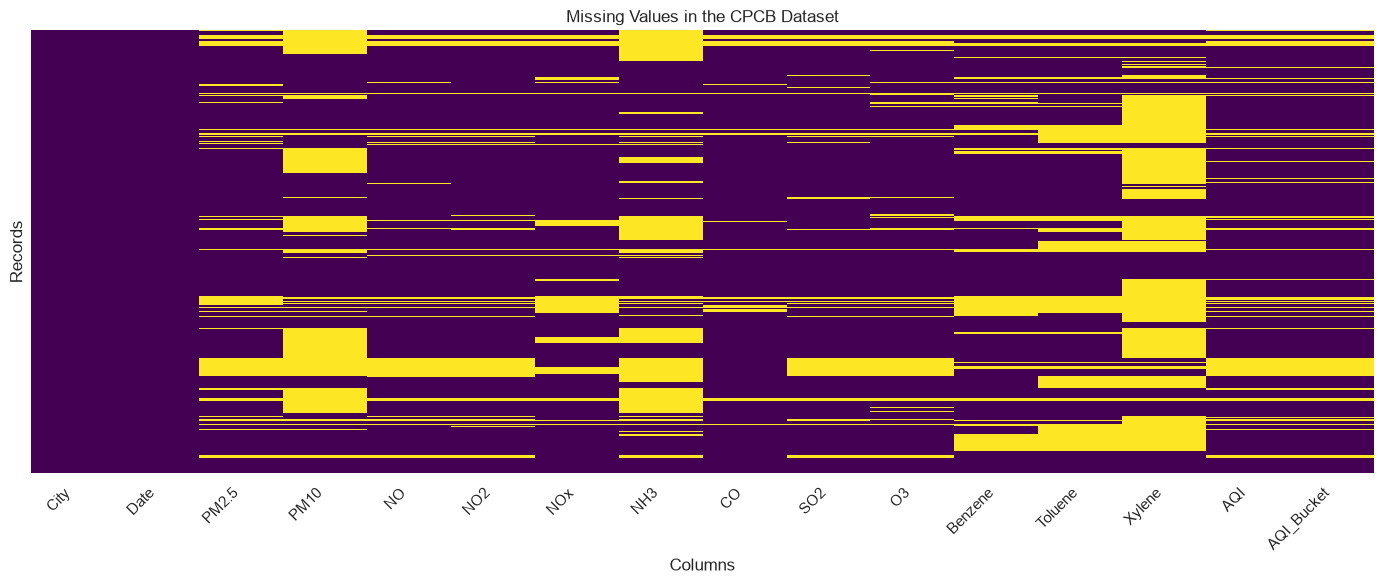

In [13]:
plt.figure(figsize=(14, 6))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values in the CPCB Dataset")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 5.3 Duplicate analysis

In [14]:
print("Duplicate complete rows:", df.duplicated().sum())

if {"City", "Date"}.issubset(df.columns):
    print("Duplicate City-Date pairs:",
          df.duplicated(subset=["City", "Date"]).sum())
else:
    print("City-Date duplicate check skipped: required columns not found.")


Duplicate complete rows: 0
Duplicate City-Date pairs: 0


## 6. City-wise record and AQI availability analysis

In [15]:
if "City" not in df.columns:
    raise KeyError("Expected a 'City' column in the dataset.")

print("Number of unique cities:", df["City"].nunique())
display(df["City"].value_counts().rename("Record Count").to_frame())


Number of unique cities: 26


,Record Count
City,
Ahmedabad,2009
Bengaluru,2009
Chennai,2009
Delhi,2009
Lucknow,2009
Mumbai,2009
Hyderabad,2006
Patna,1858
Gurugram,1679


In [16]:
if "AQI" not in df.columns:
    raise KeyError("Expected an 'AQI' target column in the dataset.")

city_aqi_summary = df.groupby("City").agg(
    Total_Records=("AQI", "size"),
    Available_AQI=("AQI", "count"),
    Missing_AQI=("AQI", lambda x: x.isna().sum()),
    Average_AQI=("AQI", "mean"),
    Median_AQI=("AQI", "median")
)
city_aqi_summary["AQI_Availability_Percentage"] = (
    city_aqi_summary["Available_AQI"] / city_aqi_summary["Total_Records"] * 100
).round(2)
display(city_aqi_summary.sort_values("Available_AQI", ascending=False))


,Total_Records,Available_AQI,Missing_AQI,Average_AQI,Median_AQI,AQI_Availability_Percentage
City,,,,,,
Delhi,2009,1999,10,259.487744,257.0,99.50
Bengaluru,2009,1910,99,94.318325,86.0,95.07
Lucknow,2009,1893,116,217.973059,198.0,94.23
Chennai,2009,1884,125,114.502654,100.0,93.78
Hyderabad,2006,1880,126,109.207447,104.0,93.72
Patna,1858,1459,399,240.782042,215.0,78.53
Gurugram,1679,1453,226,225.123882,208.0,86.54
Ahmedabad,2009,1334,675,452.122939,384.5,66.40
Visakhapatnam,1462,1171,291,117.269855,106.0,80.10


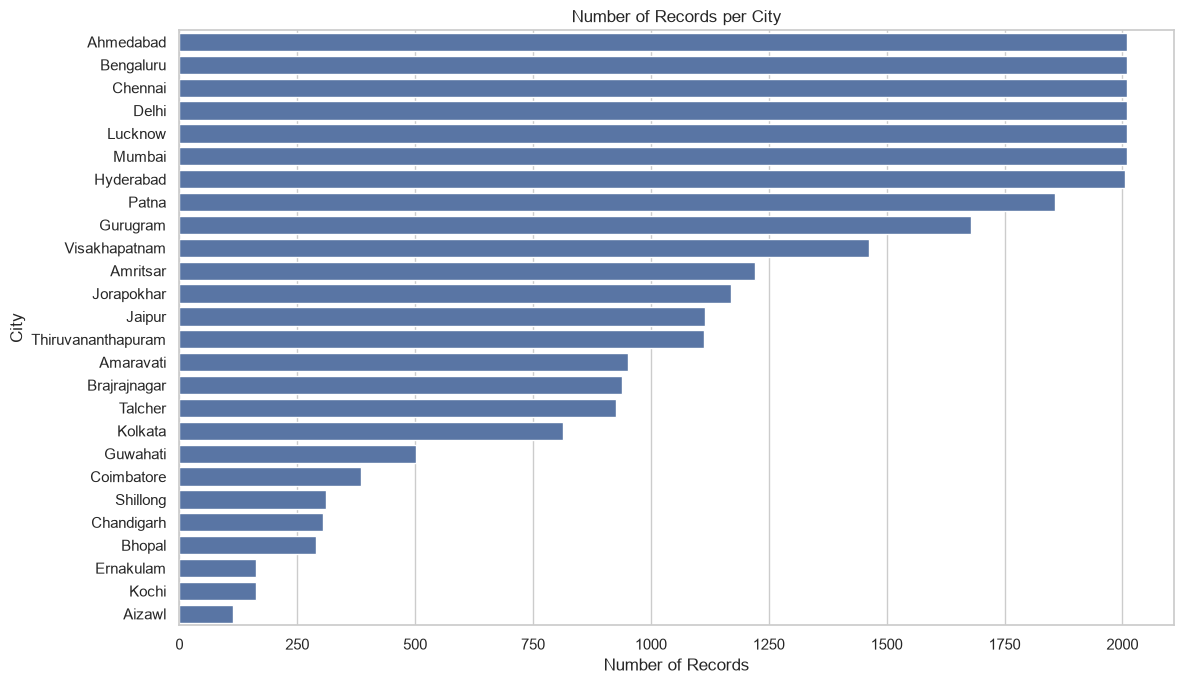

In [17]:
plt.figure(figsize=(12, 7))
sns.countplot(data=df, y="City", order=df["City"].value_counts().index)
plt.title("Number of Records per City")
plt.xlabel("Number of Records")
plt.ylabel("City")
plt.tight_layout()
plt.show()


## 7. Create a separate DataFrame for the selected cities

In [18]:
available_cities = set(df["City"].dropna().unique())
missing_cities = sorted(set(SELECTED_CITIES) - available_cities)
if missing_cities:
    print("Warning: selected cities not found:", missing_cities)

# Keep df unchanged; city_df is a separate analysis subset.
city_df = df[df["City"].isin(SELECTED_CITIES)].copy()
city_df = city_df.sort_values(["City", "Date"]).reset_index(drop=True)

print("Selected cities found:", sorted(city_df["City"].dropna().unique()))
print("Selected-city dataset shape:", city_df.shape)
display(city_df.groupby("City").size().rename("Record Count").to_frame())


Selected cities found: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow']
Selected-city dataset shape: (10042, 16)


,Record Count
City,
Bengaluru,2009
Chennai,2009
Delhi,2009
Hyderabad,2006
Lucknow,2009


## 8. AQI distribution across selected cities

### 8.1 Descriptive statistics


In [19]:
display(city_df.groupby('City')['AQI'].describe().round(2))

,count,mean,std,min,25%,50%,75%,max
City,,,,,,,,
Bengaluru,1910.0,94.32,39.91,20.0,67.0,86.0,111.0,352.0
Chennai,1884.0,114.50,51.97,30.0,78.0,100.0,136.0,449.0
Delhi,1999.0,259.49,119.54,29.0,161.5,257.0,345.5,716.0
Hyderabad,1880.0,109.21,53.14,22.0,75.0,104.0,130.0,737.0
Lucknow,1893.0,217.97,116.96,39.0,111.0,198.0,322.0,707.0


### 8.2 Boxplot

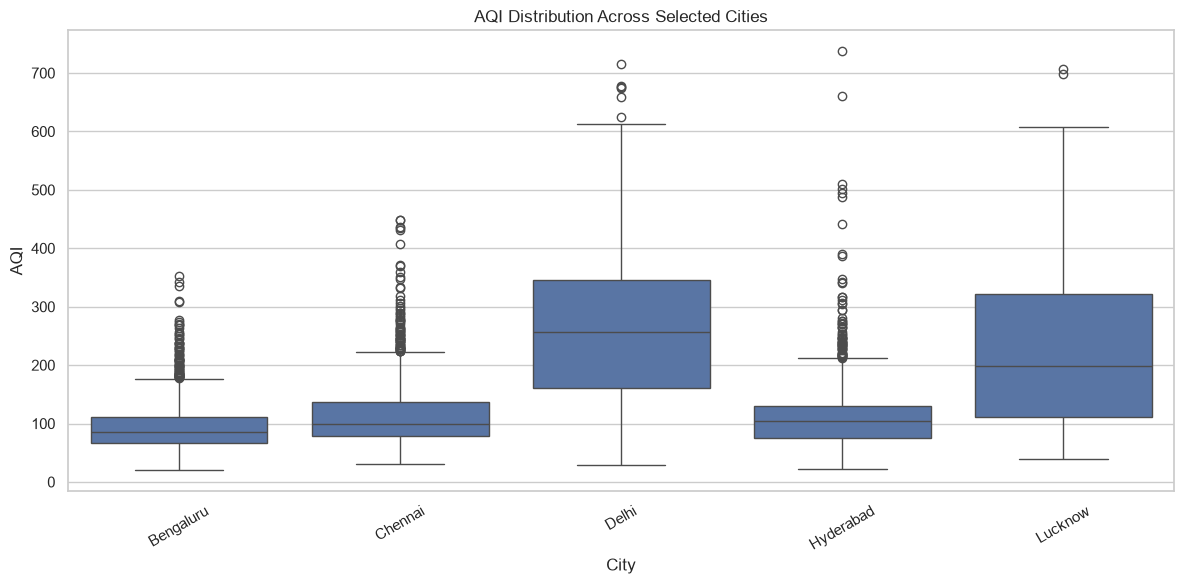

In [20]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=city_df, x="City", y="AQI")
plt.title("AQI Distribution Across Selected Cities")
plt.xlabel("City")
plt.ylabel("AQI")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### 8.3 AQI histograms

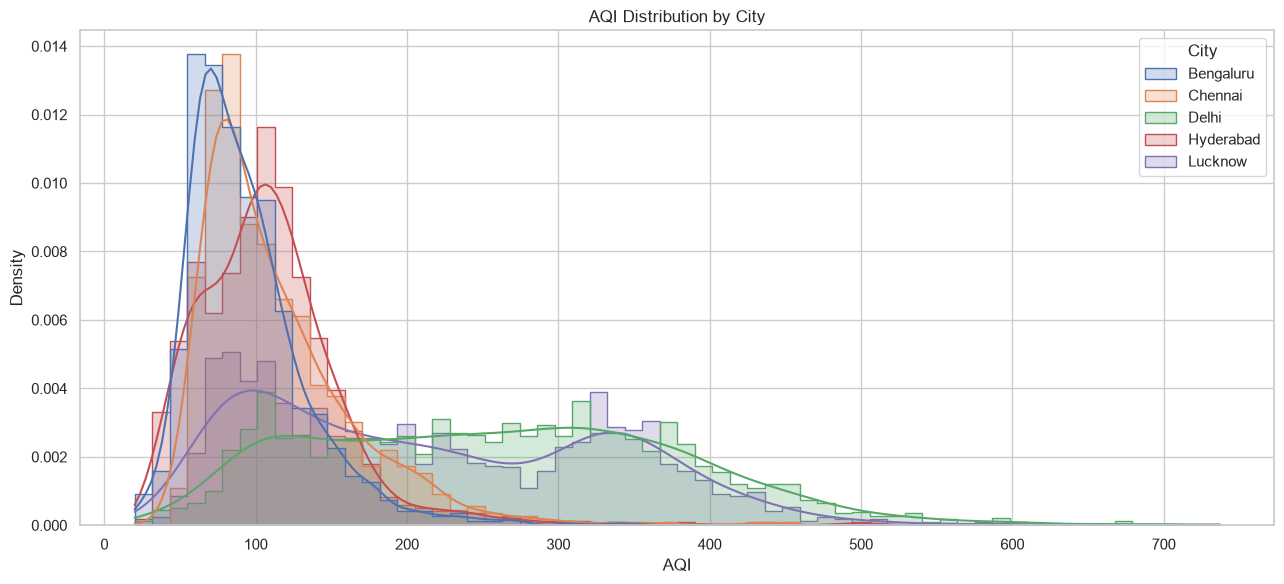

In [21]:
plt.figure(figsize=(13, 6))
sns.histplot(data=city_df, x="AQI", hue="City", element="step",
             stat="density", common_norm=False, kde=True)
plt.title("AQI Distribution by City")
plt.xlabel("AQI")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


## 9. Historical daily AQI trends

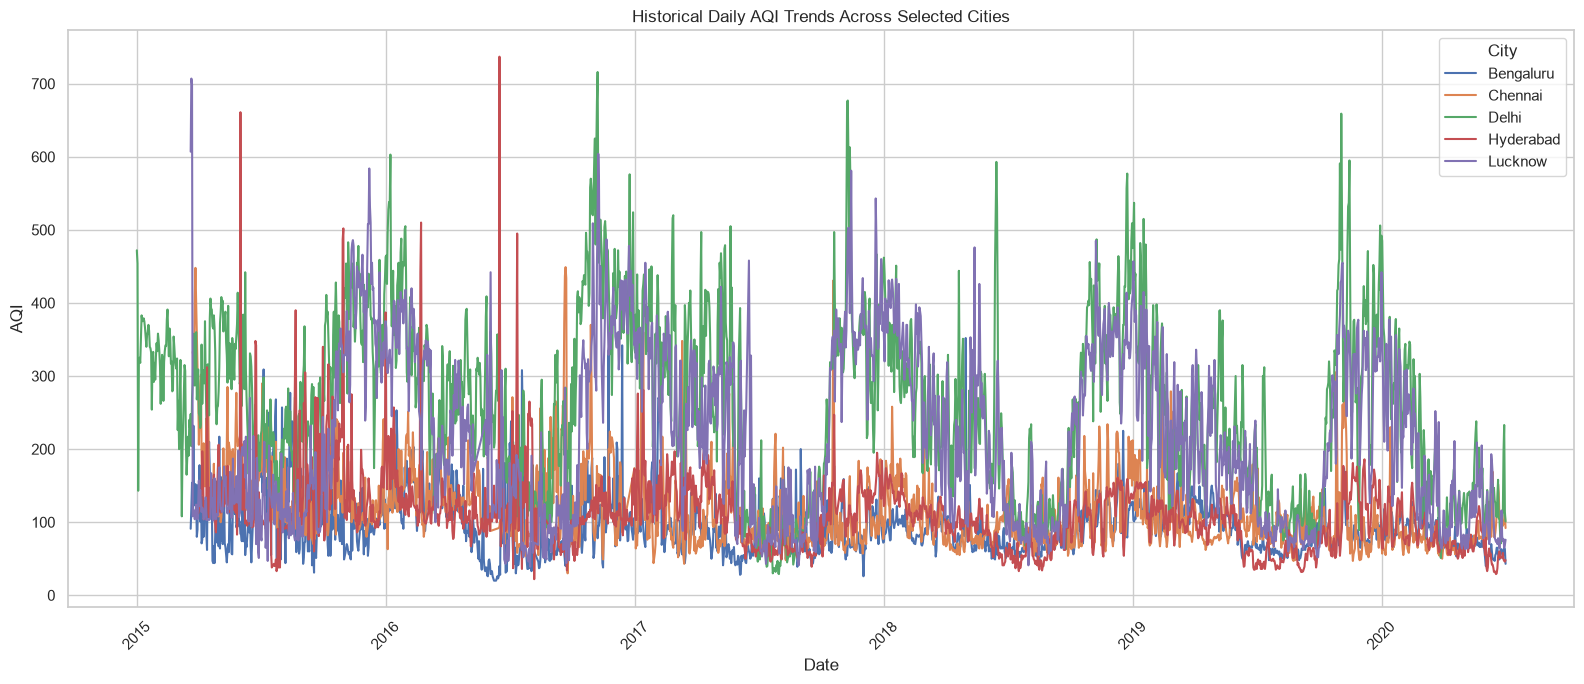

In [22]:
plt.figure(figsize=(16, 7))
sns.lineplot(data=city_df, x="Date", y="AQI", hue="City", errorbar=None)
plt.title("Historical Daily AQI Trends Across Selected Cities")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend(title="City")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 10. Monthly average AQI trends

In [23]:
monthly_aqi = (
    city_df.dropna(subset=["Date"])
    .set_index("Date")
    .groupby("City")["AQI"]
    .resample("ME")
    .mean()
    .reset_index()
)
display(monthly_aqi.head())


,City,Date,AQI
0,Bengaluru,2015-01-31,NaN
1,Bengaluru,2015-02-28,NaN
2,Bengaluru,2015-03-31,130.545455
3,Bengaluru,2015-04-30,113.733333
4,Bengaluru,2015-05-31,102.774194


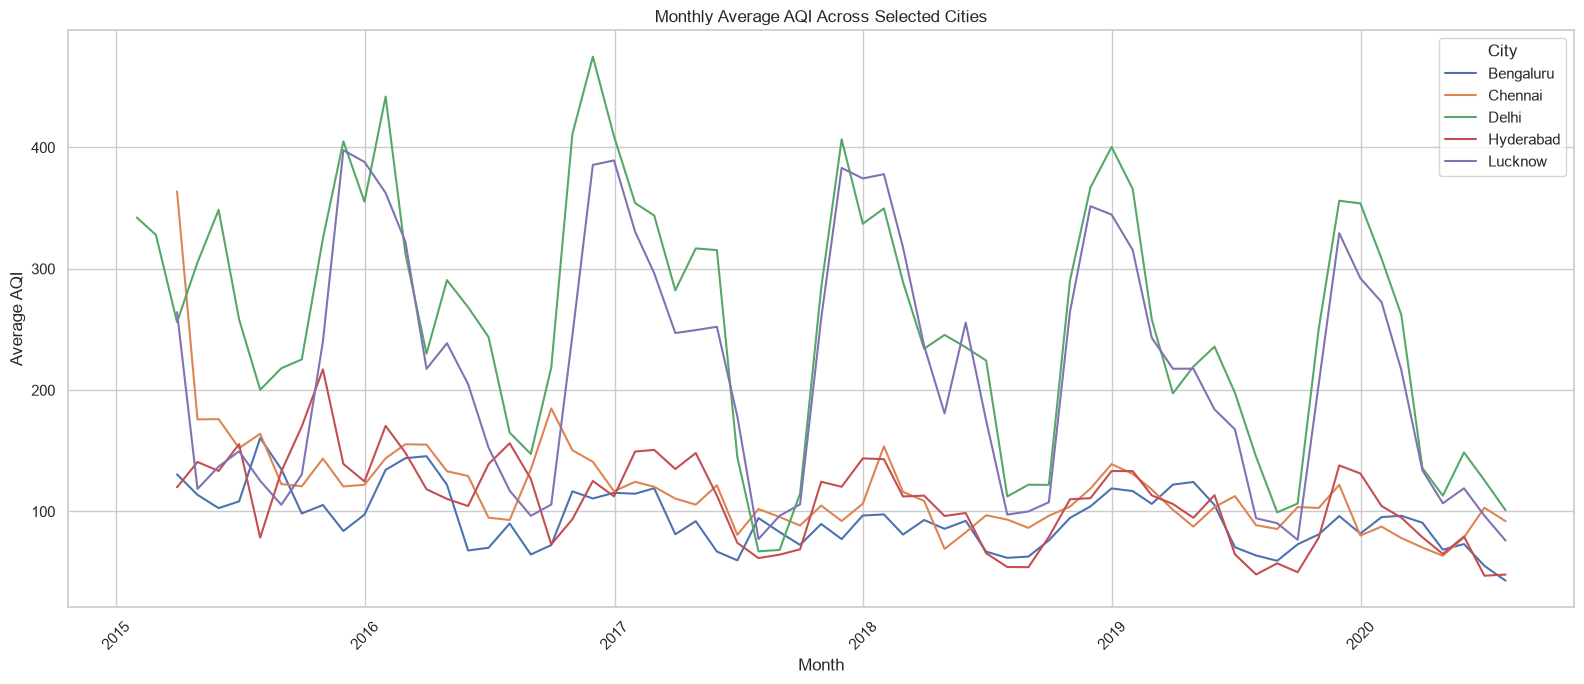

In [24]:
plt.figure(figsize=(16, 7))
sns.lineplot(data=monthly_aqi, x="Date", y="AQI", hue="City", errorbar=None)
plt.title("Monthly Average AQI Across Selected Cities")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.legend(title="City")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 11. Pollutant correlation analysis

Correlation measures the strength and direction of a linear association between numerical variables. It does not prove causation. This exploratory correlation is not, by itself, a feature-selection or forecasting decision

In [25]:
numeric_city_df = city_df.select_dtypes(include="number")
correlation_matrix = numeric_city_df.corr()

if "AQI" in correlation_matrix.columns:
    display(correlation_matrix["AQI"].sort_values(ascending=False).to_frame(
        "Correlation with AQI"
    ))
else:
    print("AQI is not available as a numerical column.")


,Correlation with AQI
AQI,1.000000
PM10,0.911826
PM2.5,0.894877
NO,0.640986
NO2,0.604166
NOx,0.586248
SO2,0.441048
O3,0.397355
Toluene,0.317453
CO,0.263770


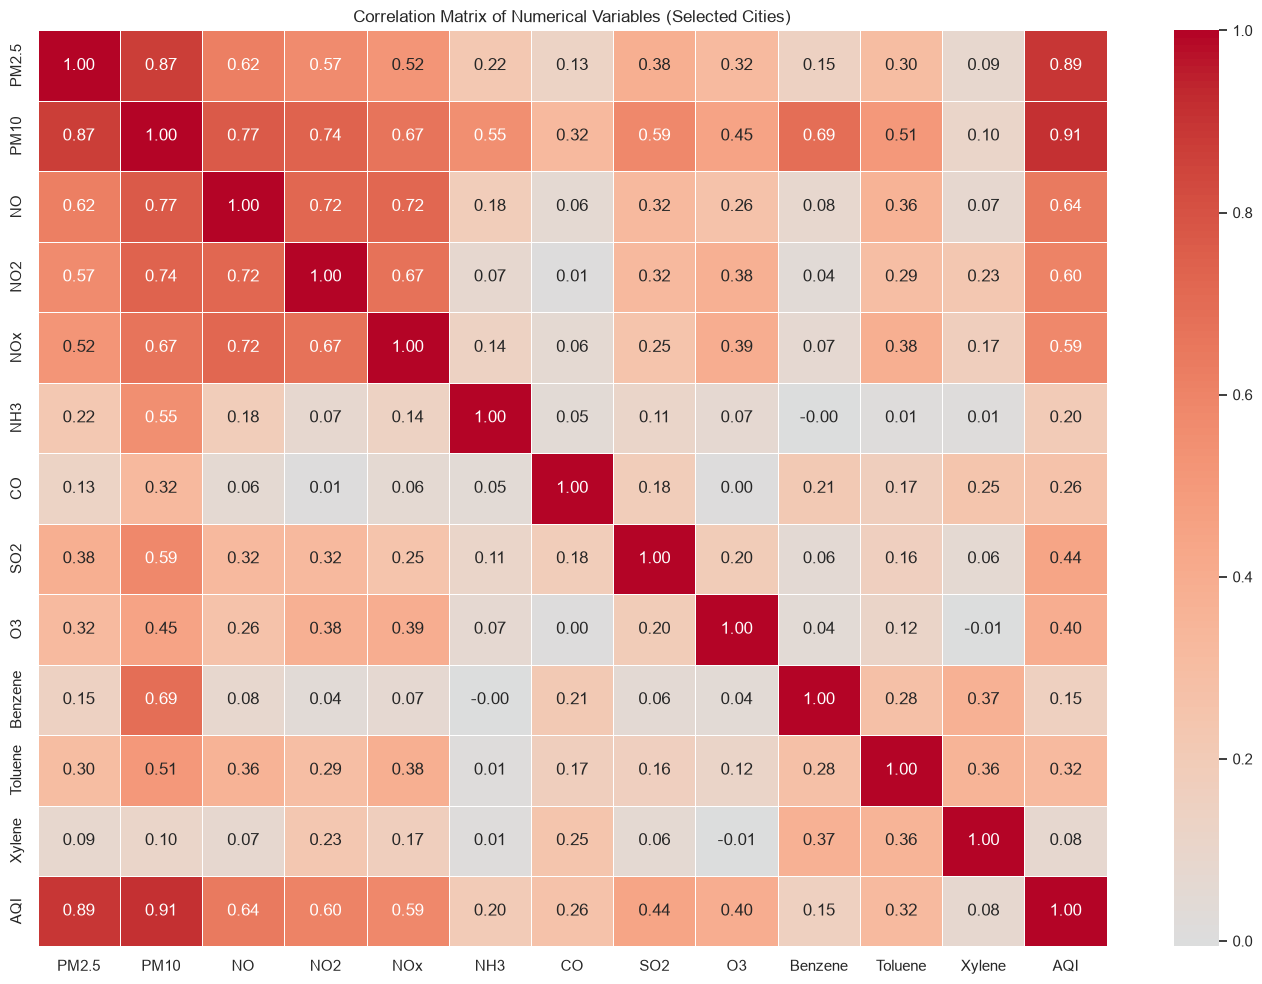

In [26]:
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm",
            center=0, fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Numerical Variables (Selected Cities)")
plt.tight_layout()
plt.show()



## 12. AQI category analysis

,Record Count
AQI_Bucket,
Moderate,3489
Satisfactory,3298
Poor,1094
Very Poor,1019
NaN,476
Severe,362
Good,304


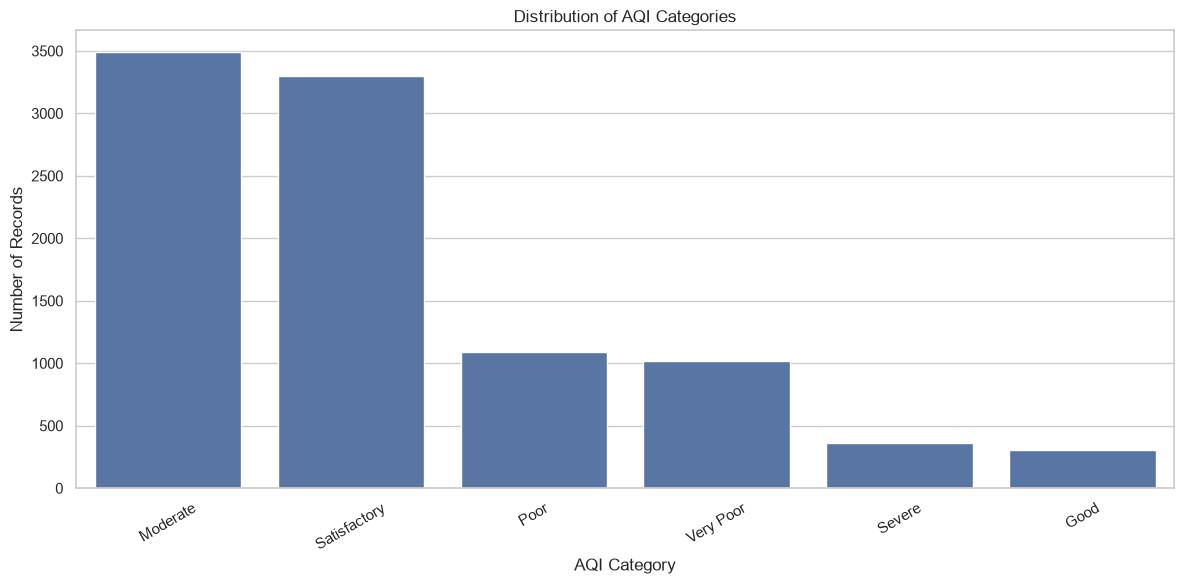

In [27]:
if "AQI_Bucket" in city_df.columns:
    display(city_df["AQI_Bucket"].value_counts(dropna=False).to_frame("Record Count"))

    plt.figure(figsize=(12, 6))
    order = city_df["AQI_Bucket"].value_counts().index
    sns.countplot(data=city_df, x="AQI_Bucket", order=order)
    plt.title("Distribution of AQI Categories")
    plt.xlabel("AQI Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("AQI_Bucket column not found; category analysis skipped.")


In [28]:
if "AQI_Bucket" in city_df.columns:
    display(pd.crosstab(city_df["City"], city_df["AQI_Bucket"], margins=True))


AQI_Bucket,Good,Moderate,Poor,Satisfactory,Severe,Very Poor,All
City,,,,,,,
Bengaluru,115,630,36,1124,0,5,1910
Chennai,12,804,110,941,6,11,1884
Delhi,21,519,542,158,239,520,1999
Hyderabad,141,958,54,710,7,10,1880
Lucknow,15,578,352,365,110,473,1893
All,304,3489,1094,3298,362,1019,9566


## 13. Date coverage and missing calendar dates

In [29]:
coverage_rows = []

for city, group in city_df.dropna(subset=["Date"]).groupby("City"):
    observed_dates = pd.DatetimeIndex(
        group["Date"].drop_duplicates().sort_values()
    )
    if len(observed_dates) == 0:
        continue

    full_range = pd.date_range(observed_dates.min(), observed_dates.max(), freq="D")
    coverage_rows.append({
        "City": city,
        "First Date": observed_dates.min(),
        "Last Date": observed_dates.max(),
        "Distinct Observed Dates": len(observed_dates),
        "Missing Calendar Dates": len(full_range.difference(observed_dates))
    })

date_coverage_summary = pd.DataFrame(coverage_rows)
display(date_coverage_summary)


,City,First Date,Last Date,Distinct Observed Dates,Missing Calendar Dates
0,Bengaluru,2015-01-01,2020-07-01,2009,0
1,Chennai,2015-01-01,2020-07-01,2009,0
2,Delhi,2015-01-01,2020-07-01,2009,0
3,Hyderabad,2015-01-04,2020-07-01,2006,0
4,Lucknow,2015-01-01,2020-07-01,2009,0


## 14. Final city-wise AQI summary

In [30]:
final_city_summary = city_df.groupby("City").agg(
    Total_Records=("AQI", "size"),
    Available_AQI=("AQI", "count"),
    Missing_AQI=("AQI", lambda x: x.isna().sum()),
    Mean_AQI=("AQI", "mean"),
    Median_AQI=("AQI", "median"),
    Minimum_AQI=("AQI", "min"),
    Maximum_AQI=("AQI", "max")
).round(2)

final_city_summary["AQI_Availability_Percentage"] = (
    final_city_summary["Available_AQI"] / final_city_summary["Total_Records"] * 100
).round(2)

display(final_city_summary)



,Total_Records,Available_AQI,Missing_AQI,Mean_AQI,Median_AQI,Minimum_AQI,Maximum_AQI,AQI_Availability_Percentage
City,,,,,,,,
Bengaluru,2009,1910,99,94.32,86.0,20.0,352.0,95.07
Chennai,2009,1884,125,114.50,100.0,30.0,449.0,93.78
Delhi,2009,1999,10,259.49,257.0,29.0,716.0,99.50
Hyderabad,2006,1880,126,109.21,104.0,22.0,737.0,93.72
Lucknow,2009,1893,116,217.97,198.0,39.0,707.0,94.23


## 15. EDA Conclusion


The Exploratory Data Analysis (EDA) was performed on the CPCB city_day.csv dataset to understand historical air-quality patterns and identify data-quality issues before developing the Next-Day AQI Forecasting System.

The following observations were made:

1. Dataset overview: The dataset contains historical air-quality observations from multiple Indian cities. The available date range is from 1 January 2015 to 1 July 2020.

2. Data quality: Missing values were identified in several pollutant columns and the AQI target column. These missing observations need to be handled carefully during preprocessing. Duplicate records were also investigated.

3. City-wise analysis: Five cities were selected for forecasting: Delhi, Bengaluru, Lucknow, Chennai and Hyderabad. Their historical AQI availability and distributions were examined separately.

4. AQI distribution: Boxplot analysis showed differences in AQI distributions across the selected cities. Several high-AQI outliers were observed, indicating occasional extreme pollution levels.

5. Historical AQI trends: Daily AQI visualisation showed considerable fluctuations over time. Delhi and Lucknow displayed particularly high AQI spikes during some periods.

6. Monthly AQI trends: Monthly aggregation was used to investigate broader changes in air quality and identify possible seasonal patterns.

7. Pollutant correlation: A correlation matrix was generated to examine the linear relationships between AQI and numerical pollutant measurements. Correlation results will be considered during feature-selection experiments, without assuming causation.

AQI categories: The AQI_Bucket column was explored to understand the distribution of different air-quality categories.

## Testing preprocessing.py

In [31]:

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATASET_PATH = PROJECT_ROOT / "dataset" / "raw" / "city_day.csv"

from src.common.preprocessing import prepare_aqi_data

city_data = prepare_aqi_data(DATASET_PATH)

for city, df in city_data.items():
    print(
        city,
        "| Shape:", df.shape,
        "| Missing AQI:", df["AQI"].isna().sum()
    )


Delhi | Shape: (2009, 3) | Missing AQI: 10
Bengaluru | Shape: (2009, 3) | Missing AQI: 99
Lucknow | Shape: (2009, 3) | Missing AQI: 116
Chennai | Shape: (2009, 3) | Missing AQI: 125
Hyderabad | Shape: (2006, 3) | Missing AQI: 126


In [32]:
delhi_dates = city_data["Delhi"]["Date"]

print(
    "Dates are continuous:",
    delhi_dates.diff().dropna().eq(pd.Timedelta(days=1)).all()
)

Dates are continuous: True


## Testing feature_engineering.py

In [33]:

from src.common.feature_engineering import (
    create_all_city_features,
    FEATURE_COLUMNS,
    TARGET_COLUMN
)

# Generate features for all five cities
city_features = create_all_city_features(city_data)

# Display the results
for city, df in city_features.items():
    print(
        city,
        "| Shape:", df.shape,
        "| Features:", len(FEATURE_COLUMNS),
        "| Target:", TARGET_COLUMN
    )


Delhi | Shape: (1958, 15) | Features: 11 | Target: target_AQI
Bengaluru | Shape: (1845, 15) | Features: 11 | Target: target_AQI
Lucknow | Shape: (1807, 15) | Features: 11 | Target: target_AQI
Chennai | Shape: (1804, 15) | Features: 11 | Target: target_AQI
Hyderabad | Shape: (1797, 15) | Features: 11 | Target: target_AQI


In [34]:
# Inspect Delhi's feature dataset
delhi_features = city_features["Delhi"]

display(delhi_features.head())

print("Feature columns:")
print(FEATURE_COLUMNS)

print("\nTarget column:")
print(TARGET_COLUMN)

print("\nMissing values:")
print(delhi_features[FEATURE_COLUMNS + [TARGET_COLUMN]].isna().sum())

,City,forecast_origin_date,Date,aqi_lag_0,aqi_lag_1,aqi_lag_2,aqi_lag_3,aqi_lag_7,rolling_mean_3,rolling_mean_7,target_dayofweek,target_month,target_dayofyear,target_is_weekend,target_AQI
0,Delhi,2015-01-08,2015-01-09,383.0,353.0,318.0,325.0,472.0,351.333333,327.857143,4.0,1.0,9.0,0,375.0
1,Delhi,2015-01-09,2015-01-10,375.0,383.0,353.0,318.0,454.0,370.333333,316.571429,5.0,1.0,10.0,1,376.0
2,Delhi,2015-01-10,2015-01-11,376.0,375.0,383.0,353.0,143.0,378.000000,349.857143,6.0,1.0,11.0,1,379.0
3,Delhi,2015-01-11,2015-01-12,379.0,376.0,375.0,383.0,319.0,376.666667,358.428571,0.0,1.0,12.0,0,375.0
4,Delhi,2015-01-12,2015-01-13,375.0,379.0,376.0,375.0,325.0,376.666667,365.571429,1.0,1.0,13.0,0,366.0


Feature columns:
['aqi_lag_0', 'aqi_lag_1', 'aqi_lag_2', 'aqi_lag_3', 'aqi_lag_7', 'rolling_mean_3', 'rolling_mean_7', 'target_dayofweek', 'target_month', 'target_dayofyear', 'target_is_weekend']

Target column:
target_AQI

Missing values:
aqi_lag_0            0
aqi_lag_1            0
aqi_lag_2            0
aqi_lag_3            0
aqi_lag_7            0
rolling_mean_3       0
rolling_mean_7       0
target_dayofweek     0
target_month         0
target_dayofyear     0
target_is_weekend    0
target_AQI           0
dtype: int64


In [35]:
print(
    delhi_features[
        ["forecast_origin_date", "Date", "aqi_lag_0", "target_AQI"]
    ].head(10)
)

  forecast_origin_date       Date  aqi_lag_0  target_AQI
0           2015-01-08 2015-01-09      383.0       375.0
1           2015-01-09 2015-01-10      375.0       376.0
2           2015-01-10 2015-01-11      376.0       379.0
3           2015-01-11 2015-01-12      379.0       375.0
4           2015-01-12 2015-01-13      375.0       366.0
5           2015-01-13 2015-01-14      366.0       353.0
6           2015-01-14 2015-01-15      353.0       340.0
7           2015-01-15 2015-01-16      340.0       356.0
8           2015-01-16 2015-01-17      356.0       360.0
9           2015-01-17 2015-01-18      360.0       370.0


## Testing splitting.py

In [36]:

from src.common.splitting import split_all_cities

# Perform 80:20 chronological split
city_splits = split_all_cities(
    city_features,
    train_ratio=0.80
)

# Display split information
for city, splits in city_splits.items():

    train_data = splits["train"]
    test_data = splits["test"]

    print(f"\n{city}")
    print("Training records:", len(train_data))
    print("Testing records:", len(test_data))

    print(
        "Training date range:",
        train_data["Date"].min(),
        "to",
        train_data["Date"].max()
    )

    print(
        "Testing date range:",
        test_data["Date"].min(),
        "to",
        test_data["Date"].max()
    )



Delhi
Training records: 1566
Testing records: 392
Training date range: 2015-01-09 00:00:00 to 2019-06-05 00:00:00
Testing date range: 2019-06-06 00:00:00 to 2020-07-01 00:00:00

Bengaluru
Training records: 1476
Testing records: 369
Training date range: 2015-03-29 00:00:00 to 2019-06-28 00:00:00
Testing date range: 2019-06-29 00:00:00 to 2020-07-01 00:00:00

Lucknow
Training records: 1445
Testing records: 362
Training date range: 2015-03-29 00:00:00 to 2019-07-05 00:00:00
Testing date range: 2019-07-06 00:00:00 to 2020-07-01 00:00:00

Chennai
Training records: 1443
Testing records: 361
Training date range: 2015-04-13 00:00:00 to 2019-07-06 00:00:00
Testing date range: 2019-07-07 00:00:00 to 2020-07-01 00:00:00

Hyderabad
Training records: 1437
Testing records: 360
Training date range: 2015-04-14 00:00:00 to 2019-07-07 00:00:00
Testing date range: 2019-07-08 00:00:00 to 2020-07-01 00:00:00


In [37]:

for city, splits in city_splits.items():

    train_data = splits["train"]
    test_data = splits["test"]

    no_overlap = (
        train_data["Date"].max() < test_data["Date"].min()
    )

    print(city, "| No chronological overlap:", no_overlap)


Delhi | No chronological overlap: True
Bengaluru | No chronological overlap: True
Lucknow | No chronological overlap: True
Chennai | No chronological overlap: True
Hyderabad | No chronological overlap: True


In [38]:
train_data = city_splits["Delhi"]["train"]
test_data = city_splits["Delhi"]["test"]

X_train = train_data[FEATURE_COLUMNS]
y_train = train_data[TARGET_COLUMN]

X_test = test_data[FEATURE_COLUMNS]
y_test = test_data[TARGET_COLUMN]

In [39]:
import importlib
import src.training.train_sarima as sarima_module

importlib.reload(sarima_module)

train_and_predict_sarima = sarima_module.train_and_predict_sarima

print("Module reloaded successfully!")

Module reloaded successfully!


In [40]:
delhi_sarima_model, delhi_sarima_predictions = (
    train_and_predict_sarima(
        city="Delhi",
        daily_data=city_data["Delhi"],
        city_split=city_splits["Delhi"]
    )
)

display(delhi_sarima_predictions.head(10))


Training SARIMA for Delhi...
Training observations: 1607
Testing calendar days: 392
Model fitting completed.


,Date,actual_AQI,predicted_AQI
0,2019-06-06,209.0,202.918243
1,2019-06-07,192.0,218.057787
2,2019-06-08,184.0,199.302941
3,2019-06-09,237.0,180.556401
4,2019-06-10,230.0,226.484968
5,2019-06-11,315.0,225.217813
6,2019-06-12,280.0,292.480788
7,2019-06-13,189.0,271.033968
8,2019-06-14,167.0,201.692967
9,2019-06-15,217.0,178.637853


In [41]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Remove dates where actual AQI is unavailable
evaluation_data = delhi_sarima_predictions.dropna(
    subset=["actual_AQI", "predicted_AQI"]
)

y_true = evaluation_data["actual_AQI"]
y_pred = evaluation_data["predicted_AQI"]

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2 = r2_score(y_true, y_pred)

print("DELHI-SARIMA EVALUATION")
print("**********")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("Evaluated records:", len(evaluation_data))


DELHI-SARIMA EVALUATION
**********
MAE: 32.29
RMSE: 45.03
R2 Score: 0.8458
Evaluated records: 392


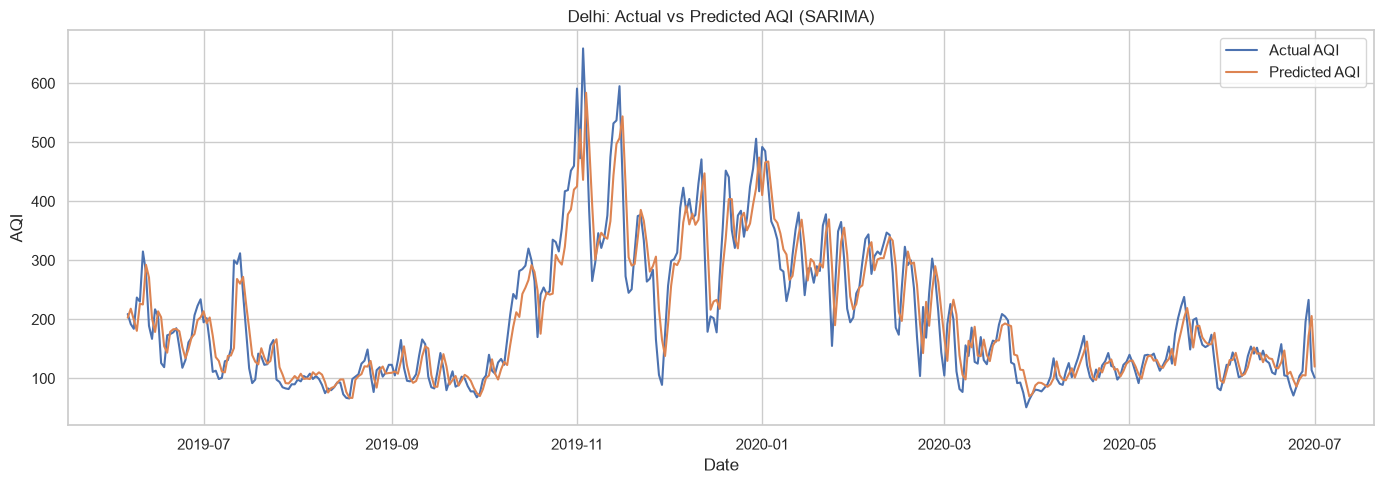

In [42]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    evaluation_data["Date"],
    y_true,
    label="Actual AQI"
)

plt.plot(
    evaluation_data["Date"],
    y_pred,
    label="Predicted AQI"
)

plt.title("Delhi: Actual vs Predicted AQI (SARIMA)")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Testing train_sarima.py

In [43]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sarima_predictions = {}
sarima_results = []

for city in city_data.keys():

    print(f"\n{'=' * 45}")
    print(f"Processing: {city}")
    print(f"{'=' * 45}")

    # Train and forecast
    model, predictions = train_and_predict_sarima(
        city=city,
        daily_data=city_data[city],
        city_split=city_splits[city]
    )

    sarima_predictions[city] = predictions

    # Evaluate only dates with actual AQI
    evaluation_data = predictions.dropna(
        subset=["actual_AQI", "predicted_AQI"]
    )

    y_true = evaluation_data["actual_AQI"]
    y_pred = evaluation_data["predicted_AQI"]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    sarima_results.append({
        "City": city,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Evaluated_Records": len(evaluation_data)
    })

    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2: {r2:.4f}")

# Create final results table
sarima_results_df = pd.DataFrame(sarima_results)

display(sarima_results_df.round(4))



Processing: Delhi

Training SARIMA for Delhi...
Training observations: 1607
Testing calendar days: 392
Model fitting completed.
MAE: 32.29
RMSE: 45.03
R2: 0.8458

Processing: Bengaluru

Training SARIMA for Bengaluru...
Training observations: 1541
Testing calendar days: 369
Model fitting completed.
MAE: 8.15
RMSE: 11.46
R2: 0.6663

Processing: Lucknow

Training SARIMA for Lucknow...
Training observations: 1531
Testing calendar days: 362
Model fitting completed.
MAE: 27.00
RMSE: 38.10
R2: 0.8592

Processing: Chennai

Training SARIMA for Chennai...
Training observations: 1523
Testing calendar days: 361
Model fitting completed.
MAE: 14.84
RMSE: 24.45
R2: 0.5334

Processing: Hyderabad

Training SARIMA for Hyderabad...
Training observations: 1520
Testing calendar days: 360
Model fitting completed.
MAE: 11.87
RMSE: 16.01
R2: 0.7977


,City,MAE,RMSE,R2,Evaluated_Records
0,Delhi,32.2934,45.0252,0.8458,392
1,Bengaluru,8.1529,11.4603,0.6663,369
2,Lucknow,26.9962,38.1047,0.8592,362
3,Chennai,14.8358,24.4502,0.5334,361
4,Hyderabad,11.8687,16.0110,0.7977,360


In [44]:
from pathlib import Path

output_dir = Path("outputs/sarima")
output_dir.mkdir(parents=True, exist_ok=True)

sarima_results_df.to_csv(
    output_dir / "sarima_metrics.csv",
    index=False
)

for city, predictions in sarima_predictions.items():
    predictions.to_csv(
        output_dir / f"{city.lower()}_predictions.csv",
        index=False
    )

print("All SARIMA results saved!")

All SARIMA results saved!


## Testing random forest model

In [45]:

from src.training.train_random_forest import (
    train_and_predict_random_forest
)

# Train Random Forest for Delhi
delhi_rf_model, delhi_rf_predictions, delhi_rf_metrics = (
    train_and_predict_random_forest(
        city="Delhi",
        city_split=city_splits["Delhi"]
    )
)

print("\nDelhi Random Forest Results:")
print(delhi_rf_metrics)

display(delhi_rf_predictions.head(10))



Training Random Forest for Delhi...
Training records: 1566
Testing records: 392
Model training completed.

Delhi Random Forest Results:
{'City': 'Delhi', 'MAE': 32.19038292947604, 'RMSE': 44.51689980555912, 'R2': 0.8492190907756372, 'Evaluated_Records': 392}


,Date,actual_AQI,predicted_AQI
0,2019-06-06,209.0,222.565284
1,2019-06-07,192.0,222.272966
2,2019-06-08,184.0,201.660505
3,2019-06-09,237.0,197.105657
4,2019-06-10,230.0,238.888440
5,2019-06-11,315.0,237.759220
6,2019-06-12,280.0,283.384480
7,2019-06-13,189.0,257.786558
8,2019-06-14,167.0,213.789329
9,2019-06-15,217.0,185.650431


In [46]:

import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Importance": delhi_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)


,Feature,Importance
0,aqi_lag_0,0.822897
6,rolling_mean_7,0.026938
9,target_dayofyear,0.026819
4,aqi_lag_7,0.024748
1,aqi_lag_1,0.022378
3,aqi_lag_3,0.021530
5,rolling_mean_3,0.021395
2,aqi_lag_2,0.018313
7,target_dayofweek,0.009715
8,target_month,0.003979


In [47]:

from src.training.train_random_forest import (
    train_all_random_forest
)

# Train Random Forest for all five cities
(
    rf_models,
    rf_predictions,
    rf_results_df
) = train_all_random_forest(city_splits)

print("\nRANDOM FOREST RESULTS")
display(rf_results_df.round(4))



Training Random Forest for Delhi...
Training records: 1566
Testing records: 392
Model training completed.
MAE: 32.19 | RMSE: 44.52 | R2: 0.8492

Training Random Forest for Bengaluru...
Training records: 1476
Testing records: 369
Model training completed.
MAE: 9.58 | RMSE: 12.87 | R2: 0.5792

Training Random Forest for Lucknow...
Training records: 1445
Testing records: 362
Model training completed.
MAE: 30.03 | RMSE: 41.08 | R2: 0.8363

Training Random Forest for Chennai...
Training records: 1443
Testing records: 361
Model training completed.
MAE: 18.28 | RMSE: 25.51 | R2: 0.4922

Training Random Forest for Hyderabad...
Training records: 1437
Testing records: 360
Model training completed.
MAE: 12.22 | RMSE: 16.65 | R2: 0.7812

RANDOM FOREST RESULTS


,City,MAE,RMSE,R2,Evaluated_Records
0,Delhi,32.1904,44.5169,0.8492,392
1,Bengaluru,9.5845,12.8699,0.5792,369
2,Lucknow,30.0268,41.0824,0.8363,362
3,Chennai,18.2760,25.5067,0.4922,361
4,Hyderabad,12.2164,16.6511,0.7812,360


## Testing train_xgboost.py


In [48]:

from src.training.train_xgboost import (
    train_and_predict_xgboost
)

# Train XGBoost for Delhi
delhi_xgb_model, delhi_xgb_predictions, delhi_xgb_metrics = (
    train_and_predict_xgboost(
        city="Delhi",
        city_split=city_splits["Delhi"]
    )
)

print("\nDelhi XGBoost Results:")
print(delhi_xgb_metrics)

display(delhi_xgb_predictions.head(10))



Training XGBoost for Delhi...
Training records: 1566
Testing records: 392
Model training completed.

Delhi XGBoost Results:
{'City': 'Delhi', 'MAE': 33.35032322941994, 'RMSE': 45.63475332826846, 'R2': 0.8415515670532199, 'Evaluated_Records': 392}


,Date,actual_AQI,predicted_AQI
0,2019-06-06,209.0,221.634003
1,2019-06-07,192.0,227.507324
2,2019-06-08,184.0,201.054489
3,2019-06-09,237.0,183.342667
4,2019-06-10,230.0,231.963806
5,2019-06-11,315.0,232.833374
6,2019-06-12,280.0,290.540771
7,2019-06-13,189.0,278.099060
8,2019-06-14,167.0,203.966949
9,2019-06-15,217.0,184.906754


In [49]:

from src.training.train_xgboost import train_all_xgboost

(
    xgb_models,
    xgb_predictions,
    xgb_results_df
) = train_all_xgboost(city_splits)

print("\nXGBOOST RESULTS")
display(xgb_results_df.round(4))



Training XGBoost for Delhi...
Training records: 1566
Testing records: 392
Model training completed.
MAE: 33.35 | RMSE: 45.63 | R2: 0.8416

Training XGBoost for Bengaluru...
Training records: 1476
Testing records: 369
Model training completed.
MAE: 9.74 | RMSE: 13.36 | R2: 0.5467

Training XGBoost for Lucknow...
Training records: 1445
Testing records: 362
Model training completed.
MAE: 32.35 | RMSE: 43.11 | R2: 0.8198

Training XGBoost for Chennai...
Training records: 1443
Testing records: 361
Model training completed.
MAE: 20.42 | RMSE: 28.45 | R2: 0.3684

Training XGBoost for Hyderabad...
Training records: 1437
Testing records: 360
Model training completed.
MAE: 12.24 | RMSE: 16.50 | R2: 0.7851

XGBOOST RESULTS


,City,MAE,RMSE,R2,Evaluated_Records
0,Delhi,33.3503,45.6348,0.8416,392
1,Bengaluru,9.7392,13.3563,0.5467,369
2,Lucknow,32.3496,43.1068,0.8198,362
3,Chennai,20.4176,28.4462,0.3684,361
4,Hyderabad,12.2363,16.5022,0.7851,360


## testing train_lstm.py

In [50]:

from src.training.train_lstm import (
    train_and_predict_lstm
)

# Train LSTM for Delhi
delhi_lstm_model, delhi_lstm_predictions, delhi_lstm_metrics = (
    train_and_predict_lstm(
        city="Delhi",
        daily_data=city_data["Delhi"],
        city_split=city_splits["Delhi"]
    )
)

print("\nDelhi LSTM Results:")
print(delhi_lstm_metrics)

display(delhi_lstm_predictions.head(10))



Training LSTM for Delhi...
Training sequences: 1570
Testing sequences: 392
Epoch 1/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0471 - val_loss: 0.0127
Epoch 2/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0157 - val_loss: 0.0114
Epoch 3/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0137 - val_loss: 0.0116
Epoch 4/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0134 - val_loss: 0.0113
Epoch 5/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0132 - val_loss: 0.0114
Epoch 6/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0127 - val_loss: 0.0110
Epoch 7/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0125 - val_loss: 0.0108
Epoch 8/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0118 - val_loss: 0.0107
Epoch 9/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0119 - val_loss: 0.0106
Epoch 10/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0114 - val_loss: 0.0104
Epoch 11/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0115 - val_

,Date,actual_AQI,predicted_AQI
0,2019-06-06,209.0,207.004257
1,2019-06-07,192.0,220.132812
2,2019-06-08,184.0,205.344269
3,2019-06-09,237.0,195.780304
4,2019-06-10,230.0,234.921677
5,2019-06-11,315.0,230.346695
6,2019-06-12,280.0,297.405762
7,2019-06-13,189.0,270.884888
8,2019-06-14,167.0,204.020447
9,2019-06-15,217.0,187.768997


In [63]:
import importlib
import src.training.train_lstm as lstm_training

# Reload the updated Python module
importlib.reload(lstm_training)

# Train LSTM models for all five cities
(
    lstm_models,
    lstm_scalers,
    lstm_predictions,
    lstm_results_df
) = lstm_training.train_all_lstm(
    city_data=city_data,
    city_splits=city_splits
)

print("\nLSTM TRAINING COMPLETED")

display(lstm_results_df.round(4))



Training LSTM for Delhi...
Training sequences: 1570
Testing sequences: 392
Epoch 1/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - loss: 0.0471 - val_loss: 0.0127
Epoch 2/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0157 - val_loss: 0.0114
Epoch 3/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0137 - val_loss: 0.0116
Epoch 4/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0134 - val_loss: 0.0113
Epoch 5/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0132 - val_loss: 0.0114
Epoch 6/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0127 - val_loss: 0.0110
Epoch 7/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0125 - val_loss: 0.0108
Epoch 8/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0118 - val_loss: 0.0107
Epoch 9/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0119 - val_loss: 0.0106
Epoch 10/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0114 - val_loss: 0.0104
Epoch 11/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0115 - val_loss: 0.

,City,MAE,RMSE,R2,Evaluated_Records
0,Delhi,32.7002,45.4521,0.8428,392
1,Bengaluru,8.7046,11.8674,0.6422,369
2,Lucknow,62.1054,70.9337,0.5120,362
3,Chennai,15.4909,24.8391,0.5184,361
4,Hyderabad,11.1645,14.8746,0.8254,360


In [64]:
print("Trained LSTM Models:")
print(list(lstm_models.keys()))

print("\nTrained LSTM Scalers:")
print(list(lstm_scalers.keys()))

assert len(lstm_models) == 5
assert len(lstm_scalers) == 5

print("\nAll five models and scalers are available!")

Trained LSTM Models:
['Delhi', 'Bengaluru', 'Lucknow', 'Chennai', 'Hyderabad']

Trained LSTM Scalers:
['Delhi', 'Bengaluru', 'Lucknow', 'Chennai', 'Hyderabad']

All five models and scalers are available!


## Final comparison table

In [52]:

# Combine results from all four models

sarima_comparison = sarima_results_df.copy()
sarima_comparison["Model"] = "SARIMA"

rf_comparison = rf_results_df.copy()
rf_comparison["Model"] = "Random Forest"

xgb_comparison = xgb_results_df.copy()
xgb_comparison["Model"] = "XGBoost"

lstm_comparison = lstm_results_df.copy()
lstm_comparison["Model"] = "LSTM"

# Merge all results
all_model_results = pd.concat(
    [
        sarima_comparison,
        rf_comparison,
        xgb_comparison,
        lstm_comparison
    ],
    ignore_index=True
)

# Arrange columns
all_model_results = all_model_results[
    ["City", "Model", "MAE", "RMSE", "R2", "Evaluated_Records"]
]

display(
    all_model_results.sort_values(
        ["City", "MAE"]
    ).round(4)
)


,City,Model,MAE,RMSE,R2,Evaluated_Records
1,Bengaluru,SARIMA,8.1529,11.4603,0.6663,369
16,Bengaluru,LSTM,8.7046,11.8674,0.6422,369
6,Bengaluru,Random Forest,9.5845,12.8699,0.5792,369
11,Bengaluru,XGBoost,9.7392,13.3563,0.5467,369
3,Chennai,SARIMA,14.8358,24.4502,0.5334,361
18,Chennai,LSTM,15.4909,24.8391,0.5184,361
8,Chennai,Random Forest,18.2760,25.5067,0.4922,361
13,Chennai,XGBoost,20.4176,28.4462,0.3684,361
5,Delhi,Random Forest,32.1904,44.5169,0.8492,392
0,Delhi,SARIMA,32.2934,45.0252,0.8458,392


In [53]:
best_models = (
    all_model_results
    .loc[all_model_results.groupby("City")["MAE"].idxmin()]
    .sort_values("City")
)

print("BEST MODEL FOR EACH CITY")
display(best_models.round(4))

BEST MODEL FOR EACH CITY


,City,Model,MAE,RMSE,R2,Evaluated_Records
1,Bengaluru,SARIMA,8.1529,11.4603,0.6663,369
3,Chennai,SARIMA,14.8358,24.4502,0.5334,361
5,Delhi,Random Forest,32.1904,44.5169,0.8492,392
19,Hyderabad,LSTM,11.1645,14.8746,0.8254,360
2,Lucknow,SARIMA,26.9962,38.1047,0.8592,362


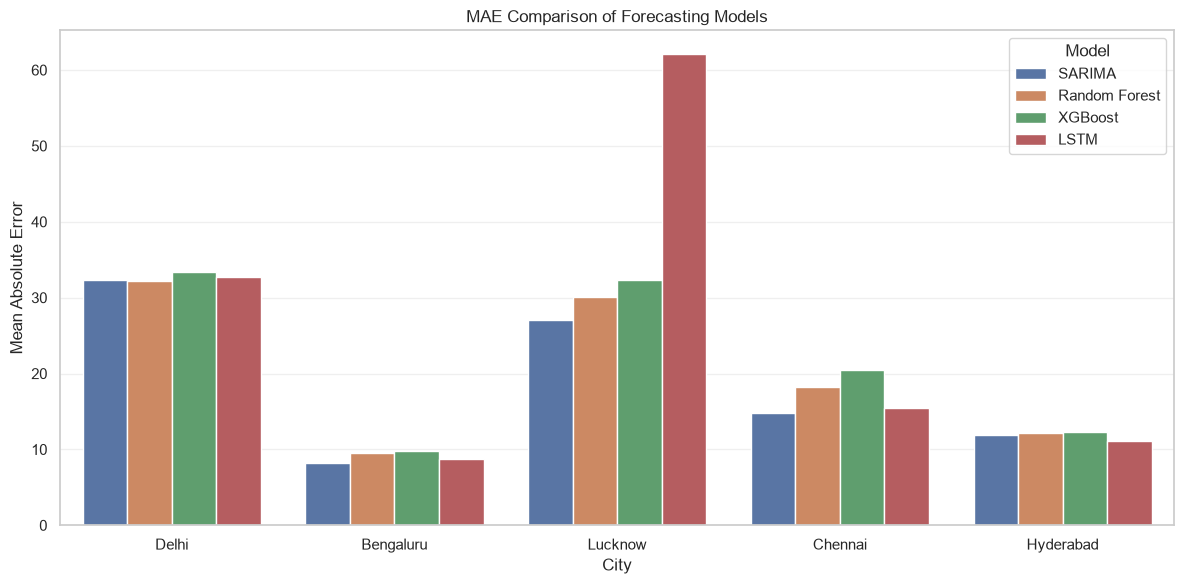

In [54]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_model_results,
    x="City",
    y="MAE",
    hue="Model"
)

plt.title("MAE Comparison of Forecasting Models")
plt.xlabel("City")
plt.ylabel("Mean Absolute Error")
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


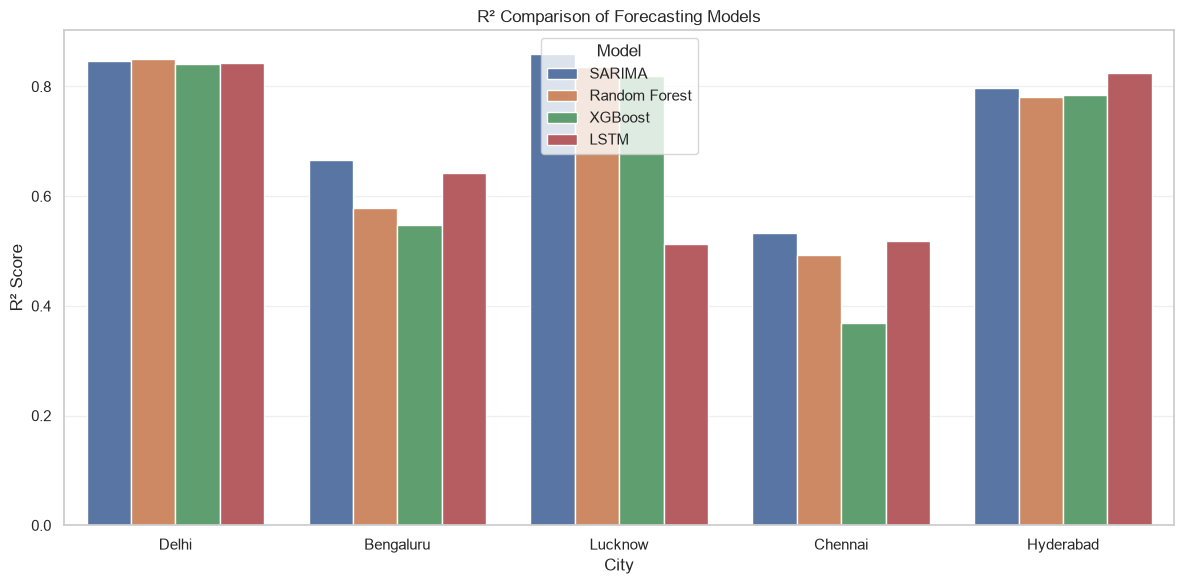

In [55]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_model_results,
    x="City",
    y="R2",
    hue="Model"
)

plt.title("R² Comparison of Forecasting Models")
plt.xlabel("City")
plt.ylabel("R² Score")
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## model saving


### 1.random_forest

In [56]:

import joblib
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

rf_model_dir = PROJECT_ROOT / "models" / "random_forest"
rf_model_dir.mkdir(parents=True, exist_ok=True)

# Save each city's trained model
for city, model in rf_models.items():

    model_path = rf_model_dir / f"{city.lower()}_rf.joblib"

    joblib.dump(model, model_path)

    print(f"Saved {city} model: {model_path.name}")

print("\nAll Random Forest models saved successfully.")


Saved Delhi model: delhi_rf.joblib
Saved Bengaluru model: bengaluru_rf.joblib
Saved Lucknow model: lucknow_rf.joblib
Saved Chennai model: chennai_rf.joblib
Saved Hyderabad model: hyderabad_rf.joblib

All Random Forest models saved successfully.


### 2.xgboost model

In [58]:

xgb_model_dir = PROJECT_ROOT / "models" / "xgboost"
xgb_model_dir.mkdir(parents=True, exist_ok=True)

for city, model in xgb_models.items():

    model_path = xgb_model_dir / f"{city.lower()}_xgb.joblib"

    joblib.dump(model, model_path)

    print(f"Saved {city} model: {model_path.name}")

print("\nAll XGBoost models saved successfully.")



Saved Delhi model: delhi_xgb.joblib
Saved Bengaluru model: bengaluru_xgb.joblib
Saved Lucknow model: lucknow_xgb.joblib
Saved Chennai model: chennai_xgb.joblib
Saved Hyderabad model: hyderabad_xgb.joblib

All XGBoost models saved successfully.


In [60]:

# Load Delhi Random Forest model
delhi_loaded_model = joblib.load(
    rf_model_dir / "delhi_rf.joblib"
)

# Make a test prediction using existing Delhi test features
sample_input = city_splits["Delhi"]["test"][FEATURE_COLUMNS].head(5)

sample_predictions = delhi_loaded_model.predict(sample_input)

print("Loaded model successfully!")
print("Sample predictions:", sample_predictions)


Loaded model successfully!
Sample predictions: [222.56528439 222.27296551 201.66050529 197.10565741 238.88844048]


### 3.sarima

In [61]:

from pathlib import Path

from src.training.train_sarima import train_and_predict_sarima

PROJECT_ROOT = Path.cwd().parent

sarima_model_dir = PROJECT_ROOT / "models" / "sarima"
sarima_model_dir.mkdir(parents=True, exist_ok=True)

sarima_models = {}

for city in city_data.keys():

    print(f"\nSaving SARIMA model for {city}...")

    model, predictions = train_and_predict_sarima(
        city=city,
        daily_data=city_data[city],
        city_split=city_splits[city]
    )

    # Keep model in memory
    sarima_models[city] = model

    # Save fitted SARIMA model
    model_path = sarima_model_dir / f"{city.lower()}_sarima.pkl"

    model.save(str(model_path))

    print(f"Saved: {model_path.name}")

print("\nAll SARIMA models saved successfully.")



Saving SARIMA model for Delhi...

Training SARIMA for Delhi...
Training observations: 1607
Testing calendar days: 392
Model fitting completed.
Saved: delhi_sarima.pkl

Saving SARIMA model for Bengaluru...

Training SARIMA for Bengaluru...
Training observations: 1541
Testing calendar days: 369
Model fitting completed.
Saved: bengaluru_sarima.pkl

Saving SARIMA model for Lucknow...

Training SARIMA for Lucknow...
Training observations: 1531
Testing calendar days: 362
Model fitting completed.
Saved: lucknow_sarima.pkl

Saving SARIMA model for Chennai...

Training SARIMA for Chennai...
Training observations: 1523
Testing calendar days: 361
Model fitting completed.
Saved: chennai_sarima.pkl

Saving SARIMA model for Hyderabad...

Training SARIMA for Hyderabad...
Training observations: 1520
Testing calendar days: 360
Model fitting completed.
Saved: hyderabad_sarima.pkl

All SARIMA models saved successfully.


In [62]:

from statsmodels.tsa.statespace.sarimax import SARIMAXResults

delhi_sarima_path = (
    sarima_model_dir / "delhi_sarima.pkl"
)

loaded_sarima = SARIMAXResults.load(
    str(delhi_sarima_path)
)

print("Delhi SARIMA model loaded successfully!")
print(loaded_sarima.summary())


Delhi SARIMA model loaded successfully!
                                     SARIMAX Results                                     
Dep. Variable:                               AQI   No. Observations:                 1617
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -8541.939
Date:                           Mon, 23 Nov 2026   AIC                          17093.877
Time:                                   16:21:35   BIC                          17120.766
Sample:                               01-01-2015   HQIC                         17103.862
                                    - 06-05-2019                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6712      0.025     26.589      0.000       0.622       0.721
ma.

### 4.lstm

In [65]:
import joblib

lstm_model_dir = PROJECT_ROOT / "models" / "lstm"
lstm_model_dir.mkdir(parents=True, exist_ok=True)

for city in lstm_models:

    # Save LSTM model
    model_path = lstm_model_dir / f"{city.lower()}_lstm.keras"
    lstm_models[city].save(model_path)

    # Save corresponding scaler
    scaler_path = lstm_model_dir / f"{city.lower()}_scaler.pkl"
    joblib.dump(lstm_scalers[city], scaler_path)

    print(f"{city}: Model and scaler saved!")

Delhi: Model and scaler saved!
Bengaluru: Model and scaler saved!
Lucknow: Model and scaler saved!
Chennai: Model and scaler saved!
Hyderabad: Model and scaler saved!


In [66]:
from pathlib import Path

lstm_model_dir = PROJECT_ROOT / "models" / "lstm"

print("Saved LSTM files:\n")

for file in sorted(lstm_model_dir.iterdir()):
    print(file.name)

print("\nTotal files:", len(list(lstm_model_dir.iterdir())))

Saved LSTM files:

bengaluru_lstm.keras
bengaluru_scaler.pkl
chennai_lstm.keras
chennai_scaler.pkl
delhi_lstm.keras
delhi_scaler.pkl
hyderabad_lstm.keras
hyderabad_scaler.pkl
lucknow_lstm.keras
lucknow_scaler.pkl

Total files: 10


In [67]:
from pathlib import Path

models_dir = PROJECT_ROOT / "models"

for folder in sorted(models_dir.iterdir()):

    if folder.is_dir():

        print(f"\n{folder.name.upper()}")

        for file in sorted(folder.iterdir()):
            print("  ", file.name)


LSTM
   bengaluru_lstm.keras
   bengaluru_scaler.pkl
   chennai_lstm.keras
   chennai_scaler.pkl
   delhi_lstm.keras
   delhi_scaler.pkl
   hyderabad_lstm.keras
   hyderabad_scaler.pkl
   lucknow_lstm.keras
   lucknow_scaler.pkl

RANDOM_FOREST
   bengaluru_rf.joblib
   chennai_rf.joblib
   delhi_rf.joblib
   hyderabad_rf.joblib
   lucknow_rf.joblib

SARIMA
   bengaluru_sarima.pkl
   chennai_sarima.pkl
   delhi_sarima.pkl
   hyderabad_sarima.pkl
   lucknow_sarima.pkl

XGBOOST
   bengaluru_xgb.joblib
   chennai_xgb.joblib
   delhi_xgb.joblib
   hyderabad_xgb.joblib
   lucknow_xgb.joblib
